# 02 · Análisis exploratorio y gráficos

**Objetivo.** Responder, con evidencia del benchmark externo (España), tres preguntas con valor para la Gerencia General de Manaco: (1) cuánto pesa la importación frente a la exportación, (2) qué socios comerciales concentran el comercio y (3) cómo varía el valor aduanero por par según categoría y flujo. Cada gráfico se cierra con una lectura empresarial.

Etiquetas usadas en la interpretación: **[Dato]** (del Excel de España), **[Supuesto]** (por analogía con Manaco) y **[Conclusión]** (afirmable con la evidencia).

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

sys.path.append(str(Path.cwd().parent / "src"))
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 200
pd.options.display.max_columns = 30

import graficos
from carga import cargar

df, _ = cargar()
print(df.shape)

(240, 10)


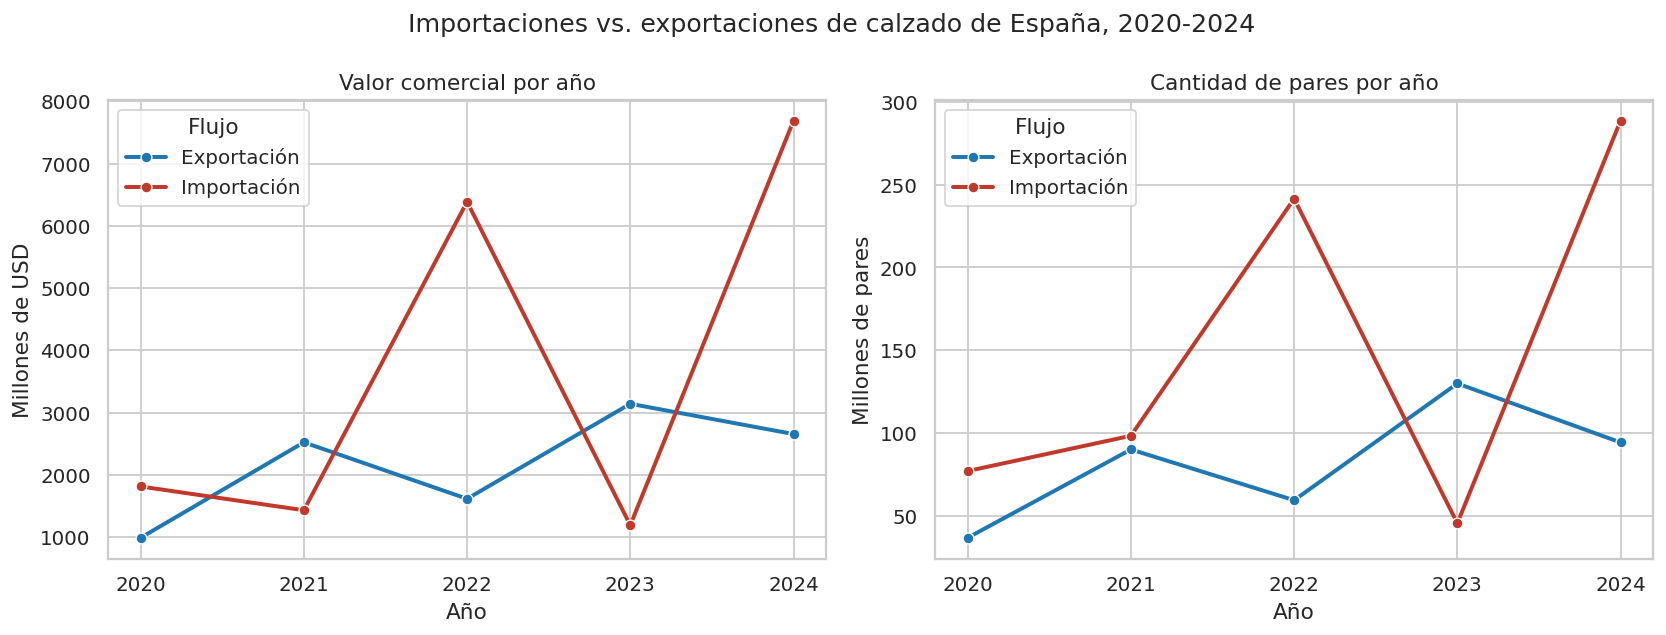

Valor (millones de USD): {'Exportación': 10917.0, 'Importación': 18506.0}
Pares (millones): {'Exportación': 410.8, 'Importación': 751.1}
Razón importación/exportación en valor: 1.7
Razón importación/exportación en pares: 1.83

Registros por flujo y año (base de la muestra):
Año              2020  2021  2022  2023  2024
Flujo_comercial                              
Exportación        15    19    18    26    42
Importación        13    15    28    24    40


In [2]:
ruta1 = graficos.grafico_import_export(df)
display(Image(filename=str(ruta1)))

tot = df.groupby("Flujo_comercial")[["Valor_USD", "Cantidad_pares"]].sum()
print("Valor (millones de USD):", (tot["Valor_USD"] / 1e6).round(0).to_dict())
print("Pares (millones):", (tot["Cantidad_pares"] / 1e6).round(1).to_dict())
print("Razón importación/exportación en valor:", round(tot.loc["Importación", "Valor_USD"] / tot.loc["Exportación", "Valor_USD"], 2))
print("Razón importación/exportación en pares:", round(tot.loc["Importación", "Cantidad_pares"] / tot.loc["Exportación", "Cantidad_pares"], 2))
print("\nRegistros por flujo y año (base de la muestra):")
print(df.groupby(["Flujo_comercial", "Año"]).size().unstack().to_string())

**Interpretación del Gráfico 1 — Importación vs. exportación**

- **[Dato]** En 2020-2024 el benchmark registra 18.506 millones de USD importados frente a 10.917 millones exportados (razón 1,7×) y 751 millones de pares importados frente a 411 millones exportados (razón 1,8×).
- **[Conclusión]** En el mercado de referencia el calzado importado es estructural: entra más volumen del que sale. **[Supuesto]** Si Bolivia replica esa lógica, la presión de importaciones baratas sobre Manaco no es coyuntural, y la defensa del mercado interno debe apoyarse en diferenciación y eficiencia de costos, no solo en precio.
- **Cautela:** las importaciones pasan de 1.190 millones de USD (2023) a 7.688 millones (2024), y el número de registros por año de la muestra cambia. Esa variación refleja en buena parte la composición de la muestra; **no debe usarse para proyectar la demanda de Manaco**. Para pronosticar se requieren las ventas internas de la empresa.

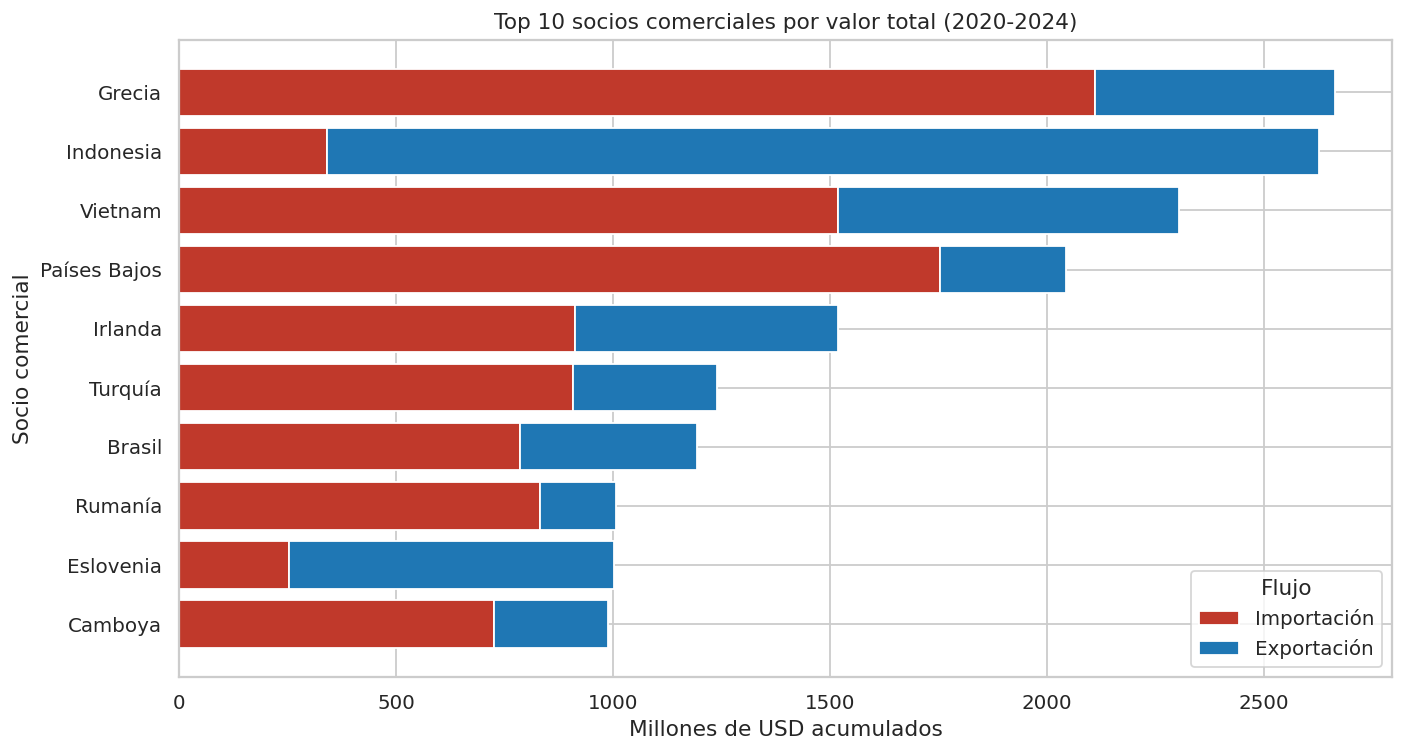

Top 10 socios (millones de USD):
Flujo_comercial  Exportación  Importación    Total
Socio_comercial                                   
Grecia                553.00     2,110.00 2,663.00
Indonesia           2,286.00       340.00 2,626.00
Vietnam               786.00     1,518.00 2,304.00
Países Bajos          291.00     1,754.00 2,045.00
Irlanda               606.00       913.00 1,519.00
Turquía               330.00       908.00 1,238.00
Brasil                407.00       786.00 1,193.00
Rumanía               177.00       831.00 1,007.00
Eslovenia             749.00       253.00 1,002.00
Camboya               264.00       725.00   989.00

Participación de los 10 primeros en el valor total: 56.4%
Top 3 proveedores en importación: Grecia, Países Bajos, Vietnam = 29.1% del valor importado
Primer destino de exportación: Indonesia = 20.9% del valor exportado


In [3]:
ruta2 = graficos.grafico_top_socios(df)
display(Image(filename=str(ruta2)))

socios = df.pivot_table(index="Socio_comercial", columns="Flujo_comercial", values="Valor_USD", aggfunc="sum", fill_value=0) / 1e6
socios["Total"] = socios.sum(axis=1)
socios = socios.sort_values("Total", ascending=False)
print("Top 10 socios (millones de USD):")
print(socios.head(10).round(0).to_string())
print(f"\nParticipación de los 10 primeros en el valor total: {socios['Total'].head(10).sum() / socios['Total'].sum():.1%}")
top3_imp = socios["Importación"].nlargest(3)
print(f"Top 3 proveedores en importación: {', '.join(top3_imp.index)} = {top3_imp.sum() / socios['Importación'].sum():.1%} del valor importado")
print(f"Primer destino de exportación: {socios['Exportación'].idxmax()} = {socios['Exportación'].max() / socios['Exportación'].sum():.1%} del valor exportado")

**Interpretación del Gráfico 2 — Principales socios comerciales**

- **[Dato]** Los 10 primeros socios concentran 56,4% del valor total; encabezan Grecia (2.663 millones de USD, sobre todo como proveedor), Indonesia (2.626 millones, sobre todo como destino de exportación), Vietnam y Países Bajos.
- **[Dato]** En importación, Grecia, Países Bajos y Vietnam suman 29,1% del valor importado; en exportación, Indonesia aporta 20,9% del valor exportado.
- **[Conclusión]** La oferta importada está relativamente diversificada (30 socios): ningún proveedor domina, de modo que la competencia llega por varias vías. **[Supuesto]** Para Manaco, esto sugiere monitorear los orígenes de las importaciones que ingresan a Bolivia por categoría en lugar de asumir un único competidor; el dato boliviano de importaciones por origen es el primer insumo que debe solicitarse.
- **Cautela:** los rankings provienen de una muestra y deben validarse contra la fuente oficial antes de presentarse como hechos de mercado.

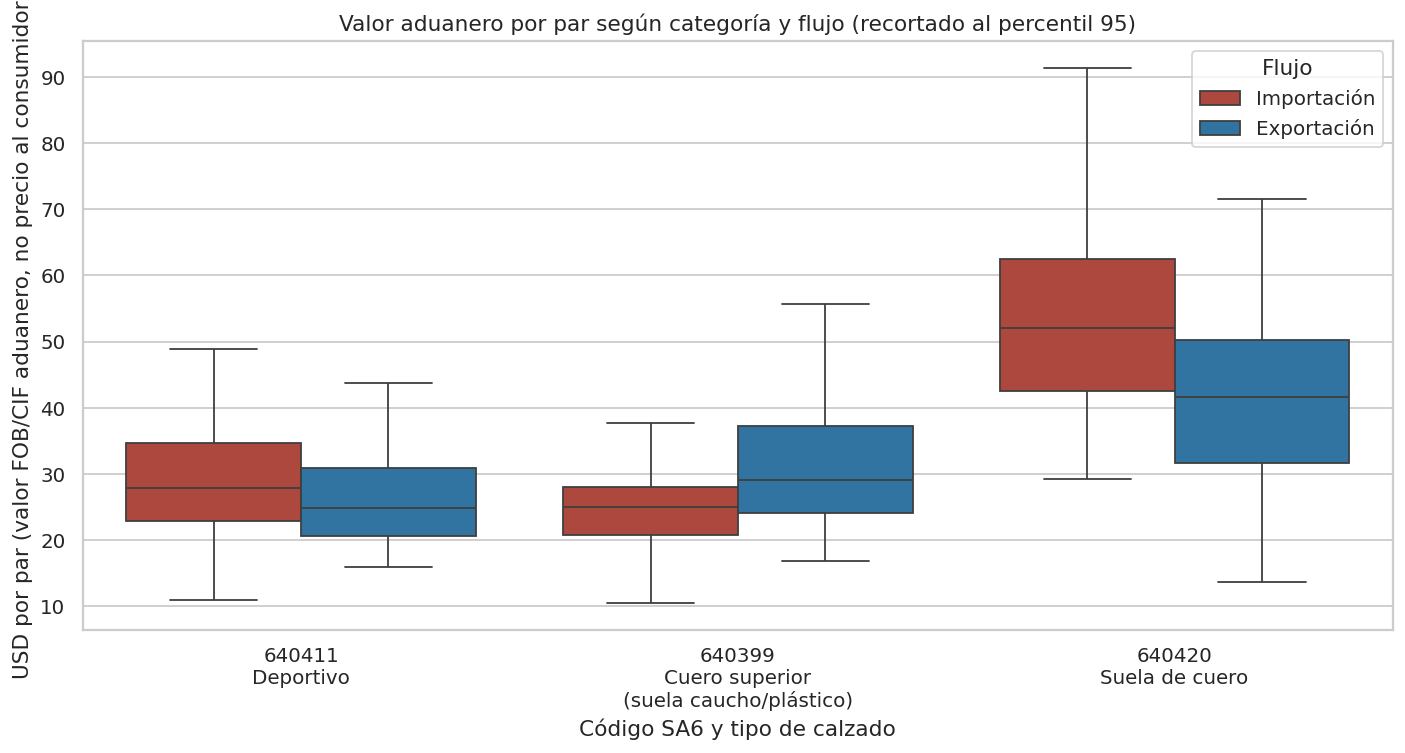

In [4]:
ruta3 = graficos.grafico_valor_par(df)
display(Image(filename=str(ruta3)))

**Interpretación del Gráfico 3 — Valor aduanero por par**

- **[Dato]** El valor medio ponderado por par es 23,54 USD (importación) y 26,54 USD (exportación) en la categoría 640399; 26,22 y 25,73 USD en el deportivo 640411; y 45,22 y 41,42 USD en 640420 (suela de cuero), la categoría de mayor valor unitario.
- **[Conclusión]** Las dos categorías de mayor volumen compiten en un rango estrecho de valor aduanero (aprox. 24-27 USD/par). La categoría 640420 es un nicho: pesa menos de 2,2% del valor, pero cada par vale cerca de 1,7 veces más.
- **Implicación para Manaco:** si sus costos por par en líneas de volumen se acercan o superan ese rango, competir solo por precio no es viable. **[Supuesto]** Las líneas de cuero y mayor calidad son candidatas a diferenciación; falta validar con el costo unitario interno.
- **Advertencia:** el valor por par es **valor aduanero (FOB/CIF)**, sin márgenes, retail, impuestos ni logística; **no es el precio al consumidor**. El gráfico recorta valores sobre el percentil 95 de cada grupo solo para legibilidad.

In [5]:
pivote = df.pivot_table(index=["Código_SA6", "Categoría_calzado"], columns="Flujo_comercial",
                        values=["Valor_USD", "Cantidad_pares"], aggfunc="sum")
pivote["Valor_USD"] = pivote["Valor_USD"] / 1e6
pivote["Cantidad_pares"] = pivote["Cantidad_pares"] / 1e6
pivote.columns = [f"{'Valor (millones USD)' if v == 'Valor_USD' else 'Pares (millones)'} · {f}" for v, f in pivote.columns]
print("Valor total y cantidad total por categoría × flujo:")
display(pivote.round(1))

Valor total y cantidad total por categoría × flujo:


,,Pares (millones) · Exportación,Pares (millones) · Importación,Valor (millones USD) · Exportación,Valor (millones USD) · Importación
Código_SA6,Categoría_calzado,,,,
640399,Calzado con suela de caucho/plástico y parte superior de cuero,320.80,497.50,"8,514.20","11,709.70"
640411,Calzado deportivo con suela de caucho/plástico,84.50,245.90,"2,173.90","6,447.50"
640420,Calzado con suela de cuero y parte superior de cuero/material similar,5.50,7.70,229.20,348.90


In [6]:
tabla_par = df.groupby(["Código_SA6", "Flujo_comercial"]).agg(
    valor=("Valor_USD", "sum"), pares=("Cantidad_pares", "sum"), media_simple=("Valor_USD_por_par", "mean")
)
tabla_par["valor_por_par_ponderado"] = tabla_par["valor"] / tabla_par["pares"]
tabla_par = tabla_par[["valor_por_par_ponderado", "media_simple"]].unstack("Flujo_comercial")
print("Valor por par (USD): ponderado = valor total / pares totales; media_simple = promedio de registros")
display(tabla_par.round(2))

Valor por par (USD): ponderado = valor total / pares totales; media_simple = promedio de registros


valor_por_par_ponderado             media_simple            
Flujo_comercial             Exportación Importación  Exportación Importación
Código_SA6                                                                  
640399                            26.54       23.54        33.11       27.13
640411                            25.73       26.22        27.51       30.05
640420                            41.42       45.22        44.72       55.97

## Hallazgos preliminares

1. **[Dato]** Las importaciones superan a las exportaciones: 1,7× en valor y 1,8× en pares.
2. **[Dato]** La categoría 640399 concentra 63,3% del valor importado y 78,0% del exportado; el deportivo (640411) pesa 34,8% en importación y 19,9% en exportación.
3. **[Dato]** El valor por par ponderado ronda 24-27 USD en las dos categorías de mayor volumen y 41-45 USD en 640420.
4. **[Dato]** El comercio está repartido entre 30 socios; los 10 primeros suman 56,4% del valor total.
5. **[Conclusión]** Los totales anuales son muy irregulares y el tamaño de la muestra por año varía: sirven para describir, no para pronosticar la demanda de Manaco.
6. **[Conclusión]** El valor por par es un valor aduanero de referencia; **no equivale al precio al consumidor**, porque excluye márgenes, impuestos, retail y logística.